# Фінальний проєкт. Завдання №5 — Довірчий інтервал різниці конверсії «кошик → покупка»

**Автор:** Мойсеєнко Світлана · **Дисципліна:** Продуктова аналітика та прикладна статистика (GoIT Neoversity)

**Запитання.** Наскільки відрізняється конверсія кроку покупки після додавання товару в кошик (`# of Purchase / # of Add to Cart`) між тестовою та контрольною групами, і який 95 % довірчий інтервал цієї різниці?

Розрахуємо інтервал трьома способами, щоб перевірити стійкість результату:

1. **На рівні користувачів (агреговані частки):** різниця двох біноміальних часток, інтервал Вальда та z-тест; додатково — інтервал Ньюкомба (на основі Вілсона), стійкіший для часток.
2. **На рівні днів:** середня щоденна конверсія в кожній групі; t-інтервал Уелча для різниці середніх (день — одиниця спостереження).
3. **Бутстреп по днях** — непараметрична перевірка результату 2.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

C_TEST, C_CONTROL = "#2a78d6", "#eb6834"
C_INK, C_MUTED, C_GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C_INK, "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

URLS = {
    "Control": "https://drive.google.com/uc?export=download&id=1OlboUFclx-9QAakDNUAMzQquH8tNzo07",
    "Test": "https://drive.google.com/uc?export=download&id=1fFIA1tJj5YQs2G7tv244tgzLhpJ5axoG",
}
FILES = {"Control": "data/control_group.csv", "Test": "data/test_group.csv"}
RENAME = {"Campaign Name": "campaign", "Date": "date", "Spend [USD]": "spend", "# of Impressions": "impressions",
          "Reach": "reach", "# of Website Clicks": "clicks", "# of Searches": "searches",
          "# of View Content": "view_content", "# of Add to Cart": "add_to_cart", "# of Purchase": "purchase"}
STEPS = ["impressions", "reach", "clicks", "searches", "view_content", "add_to_cart", "purchase"]
STEP_UA = {"impressions": "Покази", "reach": "Охоплення", "clicks": "Кліки на сайт", "searches": "Пошук на сайті",
           "view_content": "Перегляд контенту", "add_to_cart": "Додавання в кошик", "purchase": "Покупка"}

def load_group(group):
    local = Path(FILES[group])
    d = pd.read_csv(local if local.exists() else URLS[group], sep=";").rename(columns=RENAME)
    d["date"] = pd.to_datetime(d["date"], format="%d.%m.%Y")
    d["group"] = group
    return d

df = pd.concat([load_group("Control"), load_group("Test")], ignore_index=True)
row_ok = df[STEPS].notna().all(axis=1)
# день використовуємо лише тоді, коли повні дані є в ОБОХ групах — щоб порівнювати однакові періоди
df["complete"] = row_ok.groupby(df["date"]).transform("all")
print(f"Рядків: {len(df)}; рядків з пропусками: {(~row_ok).sum()}; "
      f"днів, виключених з аналізу для обох груп: {df.loc[~df.complete, 'date'].nunique()}")
df[~row_ok]

Рядків: 60; рядків з пропусками: 1; днів, виключених з аналізу для обох груп: 1


,campaign,date,spend,impressions,reach,clicks,searches,view_content,add_to_cart,purchase,group,complete
4,Control Campaign,2019-08-05,1835,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Control,False


День 05.08, за який у контрольній групі немає даних воронки, виключаємо для обох груп (залишається по 29 днів). Також перевіримо дні, де покупок більше, ніж додавань у кошик — для таких днів конверсія кроку перевищує 100 %, що фізично неможливо й указує на проблему трекінгу.

In [2]:
d = df[df.complete].copy()
d["cr_cart"] = d.purchase / d.add_to_cart
anom = d[d.cr_cart > 1][["group", "date", "add_to_cart", "purchase", "cr_cart"]]
print("Дні з конверсією кошик → покупка > 100 %:")
anom

Дні з конверсією кошик → покупка > 100 %:


,group,date,add_to_cart,purchase,cr_cart
29,Control,2019-08-30,442.0,670.0,1.5158


## 1. Агрегований підхід: різниця часток (користувачі як одиниця)

Усі додавання в кошик за 29 днів розглядаємо як «спроби», а покупки — як «успіхи». Це найпотужніший підхід (десятки тисяч спостережень), але він припускає незалежність подій і однорідність днів.

In [3]:
def two_prop(x1, n1, x2, n2, alpha=0.05):
    p1, p2 = x1 / n1, x2 / n2
    diff = p1 - p2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z = stats.norm.ppf(1 - alpha / 2)
    pp = (x1 + x2) / (n1 + n2)
    zstat = diff / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    return {"Test": p1, "Control": p2, "diff": diff, "lo": diff - z * se, "hi": diff + z * se,
            "z": zstat, "p": 2 * stats.norm.sf(abs(zstat))}

def wilson(x, n, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2)
    p = x / n; denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def newcombe(x1, n1, x2, n2, alpha=0.05):
    # Newcombe (1998) hybrid score interval for p1 - p2
    l1, u1 = wilson(x1, n1, alpha); l2, u2 = wilson(x2, n2, alpha)
    p1, p2 = x1 / n1, x2 / n2
    diff = p1 - p2
    lo = diff - np.sqrt((p1 - l1)**2 + (u2 - p2)**2)
    hi = diff + np.sqrt((u1 - p1)**2 + (p2 - l2)**2)
    return lo, hi

T = d[d.group == "Test"]; C = d[d.group == "Control"]
xT, nT = int(T.purchase.sum()), int(T.add_to_cart.sum())
xC, nC = int(C.purchase.sum()), int(C.add_to_cart.sum())
res = two_prop(xT, nT, xC, nC)
nc_lo, nc_hi = newcombe(xT, nT, xC, nC)

print(f"Test:    {xT:>6} покупок / {nT:>6} додавань у кошик = {res['Test']:.4f}")
print(f"Control: {xC:>6} покупок / {nC:>6} додавань у кошик = {res['Control']:.4f}")
print(f"\nРізниця (Test − Control): {res['diff']:+.4f}  ({res['diff']*100:+.2f} п.п.)")
print(f"95% ДІ (Вальд):     [{res['lo']:+.4f}; {res['hi']:+.4f}]")
print(f"95% ДІ (Ньюкомб):   [{nc_lo:+.4f}; {nc_hi:+.4f}]")
print(f"z = {res['z']:.2f}, p-value = {res['p']:.2e}")

Test:     14869 покупок /  25490 додавань у кошик = 0.5833
Control:  15161 покупок /  37700 додавань у кошик = 0.4021

Різниця (Test − Control): +0.1812  (+18.12 п.п.)
95% ДІ (Вальд):     [+0.1734; +0.1890]
95% ДІ (Ньюкомб):   [+0.1733; +0.1890]
z = 44.74, p-value = 0.00e+00


## 2. Поденний підхід: день як одиниця спостереження

Щоденні конверсії відображають природну мінливість між днями (сезонність, зміни ставок, аномалії трекінгу), тому інтервал виходить ширшим і чеснішим щодо невизначеності. Використовуємо t-інтервал Уелча (різні дисперсії, різна кількість днів).

In [4]:
def welch_ci(a, b, alpha=0.05):
    a, b = np.asarray(a, float), np.asarray(b, float)
    diff = a.mean() - b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    dof = (va + vb)**2 / (va**2 / (len(a) - 1) + vb**2 / (len(b) - 1))
    tcrit = stats.t.ppf(1 - alpha / 2, dof)
    t_stat, p = stats.ttest_ind(a, b, equal_var=False)
    return {"Test": a.mean(), "Control": b.mean(), "diff": diff, "lo": diff - tcrit * se, "hi": diff + tcrit * se,
            "t": t_stat, "dof": dof, "p": p}

daily_all = welch_ci(T.cr_cart, C.cr_cart)
clean = d[d.cr_cart <= 1]
daily_clean = welch_ci(clean.loc[clean.group == "Test", "cr_cart"], clean.loc[clean.group == "Control", "cr_cart"])

summary = pd.DataFrame({
    "Агреговано (Вальд)": {"Test": res["Test"], "Control": res["Control"], "Різниця": res["diff"], "95% ДІ нижня": res["lo"], "95% ДІ верхня": res["hi"], "p-value": res["p"]},
    "Агреговано (Ньюкомб)": {"Test": res["Test"], "Control": res["Control"], "Різниця": res["diff"], "95% ДІ нижня": nc_lo, "95% ДІ верхня": nc_hi, "p-value": res["p"]},
    "По днях (усі дні)": {"Test": daily_all["Test"], "Control": daily_all["Control"], "Різниця": daily_all["diff"], "95% ДІ нижня": daily_all["lo"], "95% ДІ верхня": daily_all["hi"], "p-value": daily_all["p"]},
    "По днях (без аномалії 30.08)": {"Test": daily_clean["Test"], "Control": daily_clean["Control"], "Різниця": daily_clean["diff"], "95% ДІ нижня": daily_clean["lo"], "95% ДІ верхня": daily_clean["hi"], "p-value": daily_clean["p"]},
})
summary.style.format("{:.4f}")

,Агреговано (Вальд),Агреговано (Ньюкомб),По днях (усі дні),По днях (без аномалії 30.08)
Test,0.5833,0.5833,0.6116,0.6116
Control,0.4021,0.4021,0.4572,0.4194
Різниця,0.1812,0.1812,0.1544,0.1922
95% ДІ нижня,0.1734,0.1733,0.0367,0.1010
95% ДІ верхня,0.1890,0.1890,0.2720,0.2833
p-value,0.0000,0.0000,0.0113,0.0001


## 3. Бутстреп по днях (непараметрична перевірка)

Бутстреп (10 000 повторень): різниця = +0.1548, 95% ДІ = [+0.0354; +0.2577]


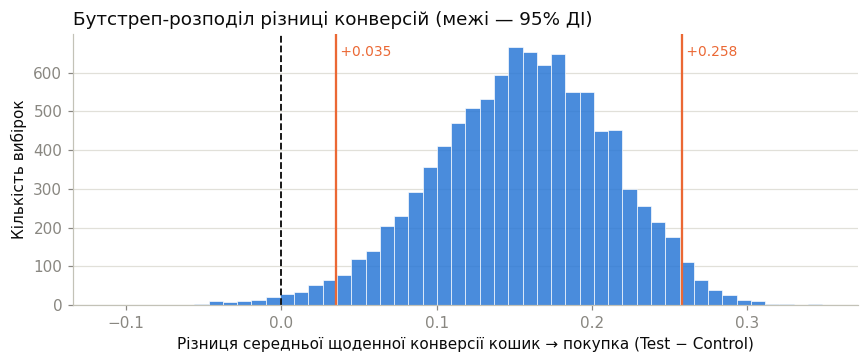

In [5]:
rng = np.random.default_rng(42)
a, b = T.cr_cart.to_numpy(), C.cr_cart.to_numpy()
boot = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10_000)])
b_lo, b_hi = np.percentile(boot, [2.5, 97.5])
print(f"Бутстреп (10 000 повторень): різниця = {boot.mean():+.4f}, 95% ДІ = [{b_lo:+.4f}; {b_hi:+.4f}]")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(boot, bins=50, color=C_TEST, alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=C_INK, lw=1.2, ls="--")
ax.axvline(b_lo, color=C_CONTROL, lw=1.5); ax.axvline(b_hi, color=C_CONTROL, lw=1.5)
ax.text(b_lo, ax.get_ylim()[1] * 0.92, f" {b_lo:+.3f}", color=C_CONTROL, fontsize=9)
ax.text(b_hi, ax.get_ylim()[1] * 0.92, f" {b_hi:+.3f}", color=C_CONTROL, fontsize=9)
ax.set_xlabel("Різниця середньої щоденної конверсії кошик → покупка (Test − Control)")
ax.set_ylabel("Кількість вибірок"); ax.grid(axis="x", visible=False)
ax.set_title("Бутстреп-розподіл різниці конверсій (межі — 95% ДІ)", loc="left", color=C_INK)
plt.tight_layout(); plt.show()

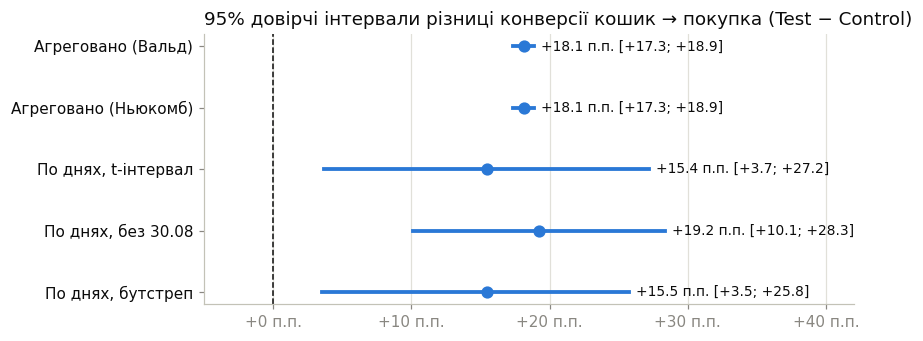

In [6]:
# Порівняння інтервалів на одному графіку
fig, ax = plt.subplots(figsize=(8, 3.2))
items = [("Агреговано (Вальд)", res["diff"], res["lo"], res["hi"]),
         ("Агреговано (Ньюкомб)", res["diff"], nc_lo, nc_hi),
         ("По днях, t-інтервал", daily_all["diff"], daily_all["lo"], daily_all["hi"]),
         ("По днях, без 30.08", daily_clean["diff"], daily_clean["lo"], daily_clean["hi"]),
         ("По днях, бутстреп", boot.mean(), b_lo, b_hi)]
for i, (name, m, lo, hi) in enumerate(items[::-1]):
    ax.plot([lo, hi], [i, i], color=C_TEST, lw=2.5); ax.plot(m, i, "o", color=C_TEST, ms=7)
    ax.text(hi + 0.005, i, f"{m*100:+.1f} п.п. [{lo*100:+.1f}; {hi*100:+.1f}]", va="center", fontsize=9, color=C_INK)
ax.axvline(0, color=C_INK, lw=1, ls="--")
ax.set_yticks(range(len(items))); ax.set_yticklabels([n for n, *_ in items[::-1]], color=C_INK)
ax.set_xlim(-0.05, 0.42); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:+.0f} п.п."))
ax.set_title("95% довірчі інтервали різниці конверсії кошик → покупка (Test − Control)", loc="left", color=C_INK)
plt.tight_layout(); plt.show()

## Висновки

1. **Конверсія «кошик → покупка» у тестовій групі істотно вища.** За агрегованими даними вона становить ≈ 58.3 % проти ≈ 40.2 % у контрольній групі; різниця **≈ +18.1 п.п., 95 % ДІ ≈ [+17.3; +18.9] п.п.** (інтервали Вальда та Ньюкомба практично збігаються), z ≈ 45, p ≈ 0. Нуль у інтервал не входить.
2. **Поденний підхід підтверджує напрям ефекту, але з більшою невизначеністю:** різниця середніх щоденних конверсій ≈ +15.4 п.п., 95 % ДІ ≈ [+3.7; +27.2] п.п. (t-інтервал Уелча, p ≈ 0.011); бутстреп дає практично ті самі межі ([+3.5; +25.8] п.п.). Після виключення аномального дня 30.08 (контроль, конверсія > 100 %, що завищує середнє контрольної групи) різниця зростає до ≈ +19.2 п.п., 95 % ДІ ≈ [+10.1; +28.3] п.п. — інтервал залишається повністю додатним.
3. **Який інтервал використовувати?** Агрегований інтервал надто «впевнений»: він вважає кожне додавання в кошик незалежним спостереженням та ігнорує щоденну мінливість і аномалії трекінгу. Для прийняття рішень коректніше спиратися на **поденний інтервал: приріст конверсії кошик → покупка щонайменше ≈ +4 п.п., найімовірніше ≈ +15–19 п.п.**
4. **Бізнес-інтерпретація.** Нове розміщення реклами приводить аудиторію, яка рідше додає товари в кошик (див. Завдання №4), але, діставшись до кошика, значно частіше завершує покупку. Це свідчить про вищу «купівельну готовність» аудиторії нового каналу. Проте сам по собі цей показник не означає, що кампанія краща загалом: кількість покупок у групах однакова, а витрати в тестовій групі вищі (Завдання №3).